# 05 · Customer Segmentation (Model 2: K-Means)
Groups all 8,000 customers into behavioural segments using **engagement, billing, tenure and satisfaction** features (PRD Model 2).
K is chosen with the **elbow method and silhouette score**, and each cluster gets a business-readable name.

*Churn and CLV are deliberately NOT used to build the clusters; they are used afterwards to describe them.*

In [4]:
import sys; sys.path.insert(0, '..')
import json, joblib, warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score
from sklearn.decomposition import PCA
from sklearn import set_config
set_config(working_memory=64)      # silhouette / Davies-Bouldin work in 64 MB chunks instead of one 488 MB distance matrix (same exact result)

PROC = Path('../data/processed'); FIG = Path('../reports/figures'); MODELS = Path('../models'); MODELS.mkdir(exist_ok=True)
sns.set_theme(style='whitegrid'); RED, GREY, BLUE, GREEN = '#E50914', '#8C8C8C', '#2B6CB0', '#2F855A'; SEED = 42
df = pd.read_csv(PROC / 'customer_features.csv')
print(f'{len(df):,} customers | overall churn {df.churned.mean():.1%}')

8,000 customers | overall churn 24.9%


## 1 · Features and preprocessing
| Theme | Feature |
|---|---|
| Tenure | `customer_tenure_days` |
| Engagement | `login_frequency`, `avg_watch_time_per_session`, `days_since_last_activity` |
| Billing | `monthly_price`, `failed_payment_rate` |
| Satisfaction / support | `avg_customer_satisfaction` (median-filled where no scored ticket), `support_ticket_count` |

Count-like skewed features are log-transformed, then everything is standardised so no feature dominates the distance.

In [5]:
LOG = ['login_frequency', 'avg_watch_time_per_session', 'support_ticket_count']
LIN = ['customer_tenure_days', 'days_since_last_activity', 'monthly_price', 'failed_payment_rate', 'avg_customer_satisfaction']
FEATS = LOG + LIN
pre = ColumnTransformer([
    ('log', Pipeline([('imp', SimpleImputer(strategy='median')), ('log', FunctionTransformer(np.log1p)), ('sc', StandardScaler())]), LOG),
    ('lin', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), LIN)])
Z = pre.fit_transform(df[FEATS]); Zdf = pd.DataFrame(Z, columns=LOG + LIN)
print(df[FEATS].describe().T[['mean', 'std', 'min', 'max']].round(2))

                               mean     std   min      max
login_frequency                0.92    0.87  0.00     5.67
avg_watch_time_per_session    40.51   24.60  0.00   240.00
support_ticket_count           0.72    0.87  0.00     7.00
customer_tenure_days        1343.63  780.14  0.00  2737.00
days_since_last_activity      36.33   32.19  0.00    90.00
monthly_price                 13.42    6.12  6.99    22.99
failed_payment_rate            0.07    0.09  0.00     1.00
avg_customer_satisfaction      3.26    1.05  1.00     5.00


## 2 · Choosing K: elbow + silhouette (+ Davies-Bouldin)

,inertia,silhouette,davies_bouldin
k,,,
2,48782.266,0.312,1.257
3,42901.637,0.188,1.946
4,38813.751,0.188,1.814
5,36142.478,0.176,1.746
6,33683.254,0.180,1.657
7,31759.809,0.174,1.558
8,30485.771,0.175,1.618
9,29153.044,0.159,1.724
10,27950.250,0.156,1.730


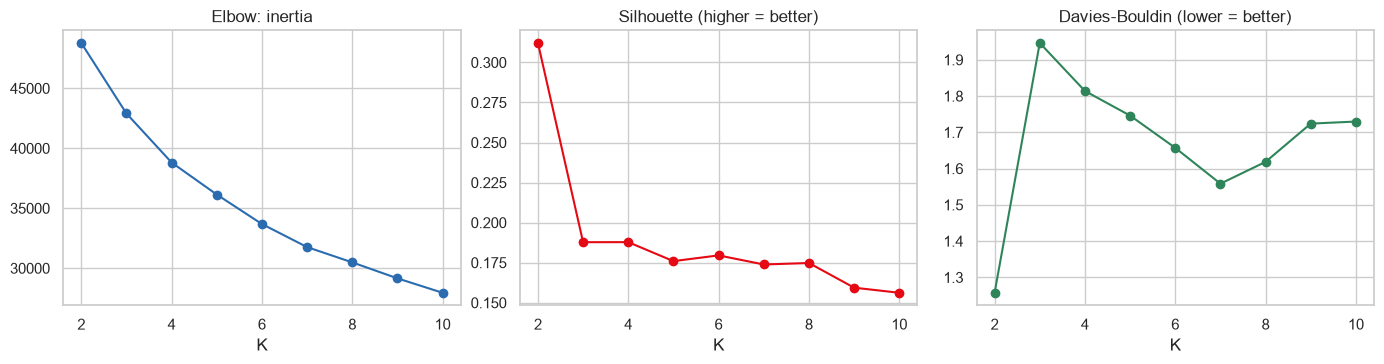

In [6]:
rows = []
for k in range(2, 11):
    km = KMeans(k, n_init=10, random_state=SEED).fit(Z)
    rows.append({'k': k, 'inertia': km.inertia_, 'silhouette': silhouette_score(Z, km.labels_), 'davies_bouldin': davies_bouldin_score(Z, km.labels_)})
sel = pd.DataFrame(rows).set_index('k'); display(sel.round(3))
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
axes[0].plot(sel.index, sel.inertia, 'o-', color=BLUE); axes[0].set_title('Elbow: inertia'); axes[0].set_xlabel('K')
axes[1].plot(sel.index, sel.silhouette, 'o-', color=RED); axes[1].set_title('Silhouette (higher = better)'); axes[1].set_xlabel('K')
axes[2].plot(sel.index, sel.davies_bouldin, 'o-', color=GREEN); axes[2].set_title('Davies-Bouldin (lower = better)'); axes[2].set_xlabel('K')
plt.tight_layout(); plt.savefig(FIG / '39_kmeans_k_selection.png', dpi=130, bbox_inches='tight'); plt.show()

In [7]:
# Rule: best silhouette among K = 3..6 (fewer than 3 is not a useful segmentation, more than 6 is not actionable)
cand = sel.loc[3:6]; K = int(cand.silhouette.idxmax())
print(f'Chosen K = {K}  (silhouette {sel.loc[K, "silhouette"]:.3f}; unconstrained best K = {int(sel.silhouette.idxmax())})')
km = KMeans(K, n_init=20, random_state=SEED).fit(Z)
# stability: does the same clustering come back with different random starts?
ari = [adjusted_rand_score(km.labels_, KMeans(K, n_init=10, random_state=s).fit(Z).labels_) for s in range(1, 6)]
print(f'Stability across 5 re-runs: mean adjusted Rand index = {np.mean(ari):.3f}')
df['segment_id'] = km.labels_

Chosen K = 4  (silhouette 0.188; unconstrained best K = 2)
Stability across 5 re-runs: mean adjusted Rand index = 0.999


## 3 · Profile the clusters

In [8]:
# Re-order cluster ids by average engagement so the numbering is meaningful and stable
order = df.groupby('segment_id').engagement_score.mean().sort_values().index
remap = {old: new for new, old in enumerate(order)}; df['segment_id'] = df.segment_id.map(remap)
cur_price = df.groupby('segment_id').monthly_price.mean()
prof = df.groupby('segment_id').agg(customers=('customer_id', 'size'), tenure_days=('customer_tenure_days', 'mean'), logins_per_month=('login_frequency', 'mean'),
        watch_min_per_session=('avg_watch_time_per_session', 'mean'), days_since_active=('days_since_last_activity', 'mean'), monthly_price=('monthly_price', 'mean'),
        failed_pay_rate=('failed_payment_rate', 'mean'), tickets=('support_ticket_count', 'mean'), csat=('avg_customer_satisfaction', 'mean'),
        engagement_score=('engagement_score', 'mean'), avg_clv=('customer_lifetime_value', 'mean'), churn_rate=('churned', 'mean'))
prof['share'] = prof.customers / len(df)
display(prof.round(2))
print('\nPlan mix (% of segment):'); display((pd.crosstab(df.segment_id, df.plan_name, normalize='index') * 100).round(0))

,customers,tenure_days,logins_per_month,watch_min_per_session,days_since_active,monthly_price,failed_pay_rate,tickets,csat,engagement_score,avg_clv,churn_rate,share
segment_id,,,,,,,,,,,,,
0,1401,1389.41,0.01,0.24,89.43,13.83,0.07,0.76,3.22,1.04,183.59,0.29,0.18
1,1417,1342.27,1.10,48.36,26.05,13.29,0.07,1.64,4.09,60.03,170.96,0.17,0.18
2,2915,1322.06,1.13,49.10,24.97,18.21,0.05,0.44,2.43,60.81,233.17,0.24,0.36
3,2267,1343.91,1.10,49.45,24.56,7.10,0.08,0.49,2.45,60.83,87.98,0.28,0.28



Plan mix (% of segment):


plan_name,Basic,Premium,Standard
segment_id,,,
0,39.0,22.0,38.0
1,41.0,17.0,42.0
2,0.0,36.0,63.0
3,99.0,0.0,1.0


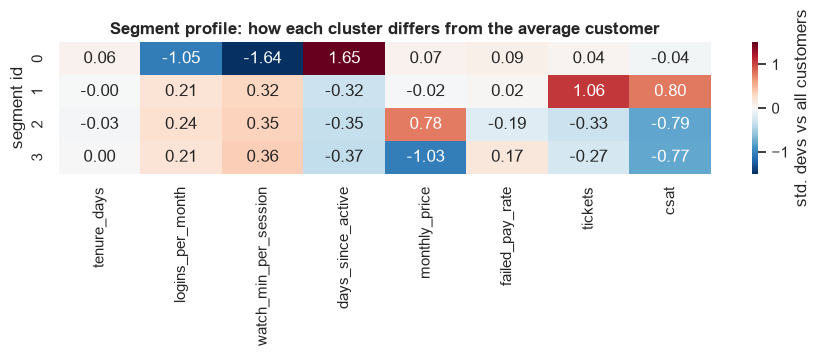

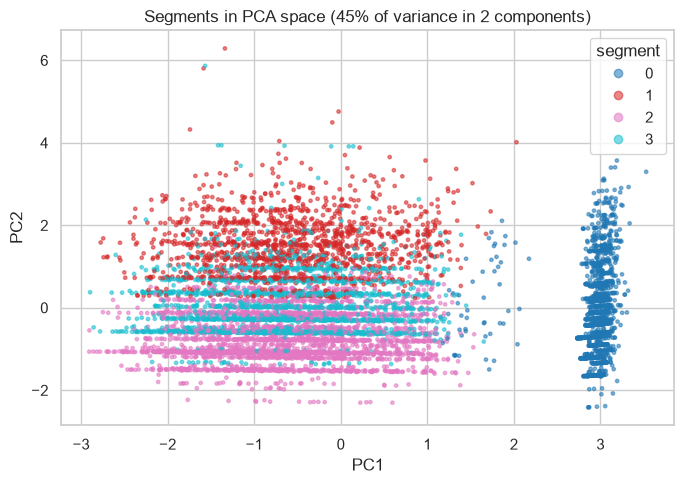

In [9]:
z = (prof[['tenure_days', 'logins_per_month', 'watch_min_per_session', 'days_since_active', 'monthly_price', 'failed_pay_rate', 'tickets', 'csat']] - df[['customer_tenure_days', 'login_frequency', 'avg_watch_time_per_session', 'days_since_last_activity', 'monthly_price', 'failed_payment_rate', 'support_ticket_count', 'avg_customer_satisfaction']].mean().values) / df[['customer_tenure_days', 'login_frequency', 'avg_watch_time_per_session', 'days_since_last_activity', 'monthly_price', 'failed_payment_rate', 'support_ticket_count', 'avg_customer_satisfaction']].std().values
fig, ax = plt.subplots(figsize=(9, 3.6)); sns.heatmap(z, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1.5, vmax=1.5, ax=ax, cbar_kws={'label': 'std. devs vs all customers'})
ax.set_title('Segment profile: how each cluster differs from the average customer', fontweight='bold'); ax.set_ylabel('segment id'); plt.tight_layout(); plt.savefig(FIG / '40_segment_profile_heatmap.png', dpi=130, bbox_inches='tight'); plt.show()
pca = PCA(2, random_state=SEED).fit(Z); P = pca.transform(Z)
fig, ax = plt.subplots(figsize=(7, 5)); sc = ax.scatter(P[:, 0], P[:, 1], c=df.segment_id, cmap='tab10', s=6, alpha=.55)
ax.set_title(f'Segments in PCA space ({pca.explained_variance_ratio_.sum():.0%} of variance in 2 components)'); ax.set_xlabel('PC1'); ax.set_ylabel('PC2'); ax.legend(*sc.legend_elements(), title='segment', loc='best')
plt.tight_layout(); plt.savefig(FIG / '41_segments_pca.png', dpi=130, bbox_inches='tight'); plt.show()

## 4 · Segment names and business meaning (K = 4)

| id | Name | Share | Churn | Avg CLV | What defines it |
|---|---|---|---|---|---|
| 0 | **Dormant Accounts** | 18% | 29% | $184 | ~no viewing in 90 days (96% inactive) |
| 1 | **Engaged & Well-Supported** | 18% | **17%** | $171 | active, most tickets (1.6) and best CSAT (4.1) |
| 2 | **High-Value Engaged (Standard/Premium)** | 36% | 24% | **$233** | active, avg price $18.21, CSAT 2.4 |
| 3 | **Budget Basic Subscribers** | 28% | 28% | $88 | 99% Basic plan ($7.10), CSAT 2.5 |

**Suggested actions**
* *Dormant Accounts:* automated re-engagement (recommendations, "new this week" emails). They are paying but not watching, so they are the next cancellations.
* *Engaged & Well-Supported:* protect. They churn least, and the pattern suggests good support experiences keep customers. No discount needed.
* *High-Value Engaged:* largest revenue pool with weak satisfaction. Proactive service-quality outreach beats price offers here.
* *Budget Basic:* upgrade nudges and bundles; keep retention spend low because lifetime value is low.

**How to read the quality of this segmentation (honest caveats)**
* The clusters are **very stable** (adjusted Rand index 0.999 across random restarts) but only **weakly separated** (silhouette 0.19, and K=2 scores higher on silhouette alone). I chose K=4 because the PRD asks for business-readable segments and K=2 would only split "active vs dormant". Silhouette values this low are normal for behavioural data with no hard boundaries.
* Segments are driven by three things: **activity vs dormancy, plan price, and support satisfaction/volume**. Tenure, failed-payment rate and age barely differ between segments, so don't over-interpret those columns.
* CSAT is only observed for customers who raised a scored ticket (26-42% depending on the segment); missing values were median-filled for clustering, which pulls those customers toward the middle.
* Churn rate and CLV were *not* used to form the clusters, so the differences in the table above are genuine findings (e.g. segment 1's 17% vs segment 0's 29%).

In [10]:
NAMES = {0: 'Dormant Accounts', 1: 'Engaged & Well-Supported', 2: 'High-Value Engaged (Standard/Premium)', 3: 'Budget Basic Subscribers'}
DESC = {0: 'Pay but almost never watch (96% had no viewing in the last 90 days). Highest churn risk and a clear win-back / re-engagement target.', 1: 'Active viewers who use support the most (1.6 tickets each) and rate it best (CSAT 4.1). Lowest churn (17%). The loyal core: protect, do not discount.', 2: 'Active Standard/Premium payers (avg $18.21/month), the highest lifetime value ($233) and 36% of the base, but low satisfaction where scored (CSAT 2.4). Churn is average (24%): fix the service experience before they leave.', 3: 'Almost all on the Basic plan ($7.10/month), low lifetime value ($88), engaged but dissatisfied (CSAT 2.5) and high churn (28%). Price-sensitive: candidates for upgrade offers or bundles, low-cost retention only.'}
df['segment_name'] = df.segment_id.map(NAMES)
prof['segment_name'] = prof.index.map(NAMES)
prof[['segment_name','customers','share','churn_rate','avg_clv','engagement_score']].round(3)

,segment_name,customers,share,churn_rate,avg_clv,engagement_score
segment_id,,,,,,
0,Dormant Accounts,1401,0.175,0.295,183.590,1.040
1,Engaged & Well-Supported,1417,0.177,0.174,170.964,60.034
2,High-Value Engaged (Standard/Premium),2915,0.364,0.243,233.175,60.807
3,Budget Basic Subscribers,2267,0.283,0.275,87.980,60.832


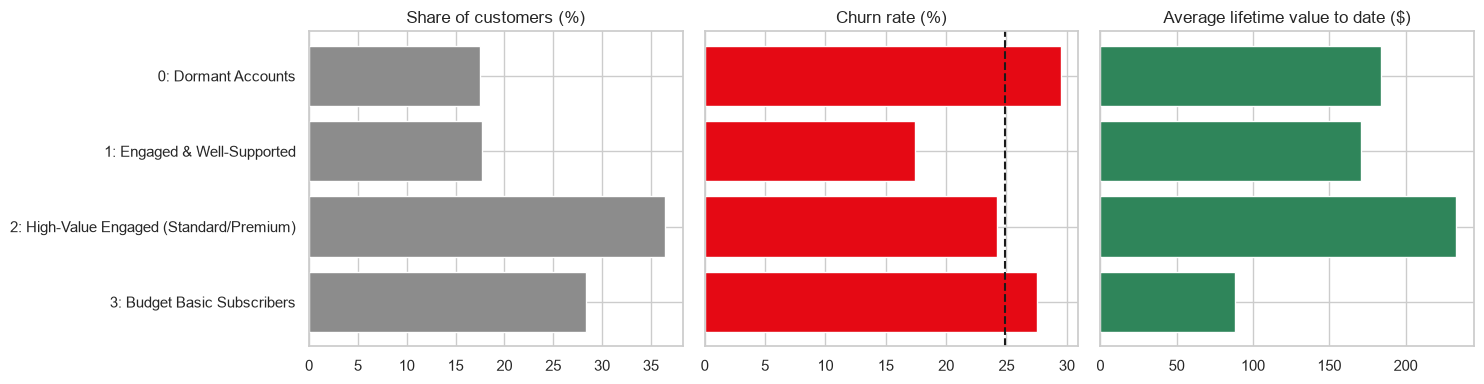

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4)); lab = [f'{i}: {NAMES[i]}' for i in prof.index]
axes[0].barh(lab, prof.share * 100, color=GREY); axes[0].set_title('Share of customers (%)'); axes[0].invert_yaxis()
axes[1].barh(lab, prof.churn_rate * 100, color=RED); axes[1].axvline(df.churned.mean() * 100, color='k', ls='--'); axes[1].set_title('Churn rate (%)'); axes[1].set_yticklabels([]); axes[1].invert_yaxis()
axes[2].barh(lab, prof.avg_clv, color=GREEN); axes[2].set_title('Average lifetime value to date ($)'); axes[2].set_yticklabels([]); axes[2].invert_yaxis()
plt.tight_layout(); plt.savefig(FIG / '42_segment_business_view.png', dpi=130, bbox_inches='tight'); plt.show()

## 4 · Save

In [12]:
joblib.dump({'pipeline': Pipeline([('pre', pre), ('km', km)]), 'features': FEATS, 'k': K, 'id_remap': remap, 'names': NAMES, 'descriptions': DESC}, MODELS / 'segmentation_model.joblib')
df[['customer_id', 'segment_id', 'segment_name']].to_csv(PROC / 'customer_segments.csv', index=False)
prof.round(4).to_csv(PROC / 'segment_profiles.csv')
print('saved models/segmentation_model.joblib, data/processed/customer_segments.csv, segment_profiles.csv'); df.segment_name.value_counts()

saved models/segmentation_model.joblib, data/processed/customer_segments.csv, segment_profiles.csv


segment_name
High-Value Engaged (Standard/Premium)    2915
Budget Basic Subscribers                 2267
Engaged & Well-Supported                 1417
Dormant Accounts                         1401
Name: count, dtype: int64